In [1]:
import os
import glob
import re
import anndata as ad
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [2]:

# 1. Define the directory containing your .h5ad files
# (Change this to your actual directory path, or use '.' for current directory)
data_dir = "/mnt/volume/Johanna_Velotest/sim_data" 
file_pattern = os.path.join(data_dir, "*.h5ad")

# Regex to extract parameters from the filename
# It makes 'total' and 'points' optional to handle both file types in your image
filename_regex = re.compile(
    r"dynamical_linear_(?P<cells>\d+)_cells_(?P<genes>\d+)_genes"
    r"(?:_(?P<total>\d+)_total)?(?:_(?P<points>\d+)_points)?_seed_(?P<seed>\d+)\.h5ad"
)

Scanning and processing files...

Generating scatter plots...


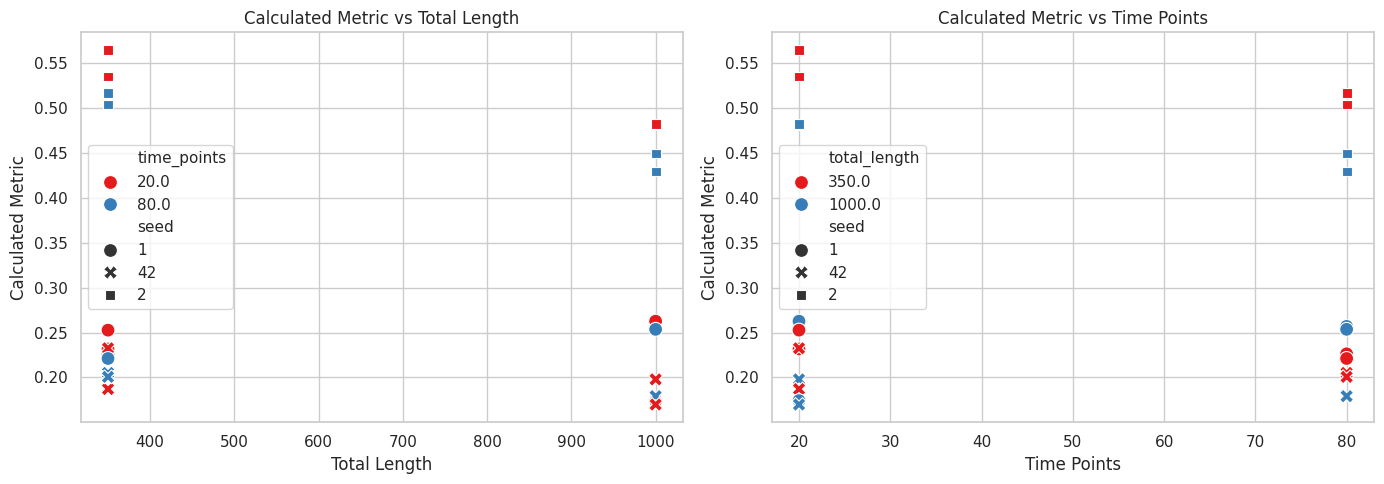

In [3]:

# List to hold the extracted data
results = []

# 2. Iterate through files, read them, and extract information
print("Scanning and processing files...")
for filepath in glob.glob(file_pattern):
    filename = os.path.basename(filepath)
    match = filename_regex.search(filename)
    
    if match:
        # Extract metadata from filename
        cells = int(match.group('cells'))
        genes = int(match.group('genes'))
        # Handle optional parameters (will be None if not in filename)
        total_len = int(match.group('total')) if match.group('total') else np.nan
        points = int(match.group('points')) if match.group('points') else np.nan
        seed = str(match.group('seed'))
        
        # Load the AnnData object
        try:
            adata = ad.read_h5ad(filepath)
            
            # --- REPLACE THIS WITH YOUR ACTUAL CALCULATION ---
            # Example calculation: Mean expression of all genes across all cells
            # Or extracting a specific metric from adata.uns or adata.obs
            if hasattr(adata.obsm['general_bound'], 'mean'):
                calc_metric = adata.obsm['general_bound'].mean()
            else:
                calc_metric = np.nan 
            # -------------------------------------------------
            
            # Store the results
            results.append({
                "filename": filename,
                "cells": cells,
                "genes": genes,
                "total_length": total_len,
                "time_points": points,
                "seed": seed,
                "general_bound": calc_metric # The data you want to plot
            })
            
        except Exception as e:
            print(f"Error reading {filename}: {e}")

# 3. Convert collected data to a DataFrame
# 3. Convert collected data to a DataFrame
df = pd.DataFrame(results)

# Drop rows that don't have 'total_length' or 'time_points'
plot_df = df.dropna(subset=['total_length', 'time_points']).copy()

# 4. Generate Scatter Plots
if not plot_df.empty:
    print("\nGenerating scatter plots...")
    sns.set_theme(style="whitegrid")
    
    # Create a figure with two subplots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Plot A: Metric vs Total Length (Dots only)
    # hue="seed" colors by seed, style="seed" gives each seed a different marker shape
    sns.scatterplot(
        data=plot_df, 
        x="total_length", 
        y="general_bound", 
        hue="time_points", 
        style="seed", 
        palette="Set1", # Use a discrete color palette
        s=100,          # Size of the dots
        ax=axes[0]
    )
    axes[0].set_title("Calculated Metric vs Total Length")
    axes[0].set_xlabel("Total Length")
    axes[0].set_ylabel("Calculated Metric")
    
    # Plot B: Metric vs Time Points (Dots only)
    sns.scatterplot(
        data=plot_df, 
        x="time_points", 
        y="general_bound", 
        hue="total_length", # Color by total_length for this plot
        style="seed",
        palette="Set1",
        s=100,
        ax=axes[1]
    )
    axes[1].set_title("Calculated Metric vs Time Points")
    axes[1].set_xlabel("Time Points")
    axes[1].set_ylabel("Calculated Metric")
    
    plt.tight_layout()
    plt.show()
    
else:
    print("\nNo files with 'total' and 'points' parameters were found for plotting.")

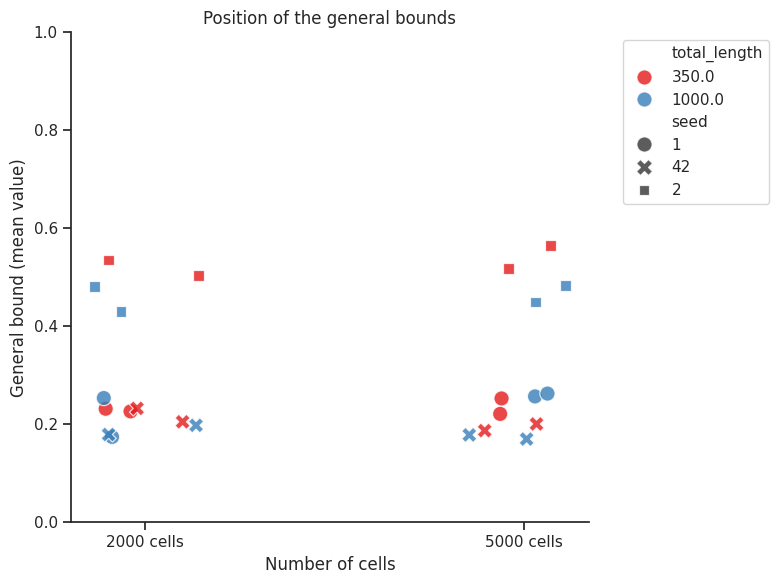

In [4]:
# 1. Change the theme to remove the background grid lines!
sns.set_theme(style="ticks") 

plt.figure(figsize=(8, 6))

# Map cell counts to base positions
unique_cells = sorted(plot_df['cells'].unique())
cell_to_x = {cells: i for i, cells in enumerate(unique_cells)}

# Add a simple random spread (jitter)
np.random.seed(42)
plot_df['x_jittered'] = plot_df['cells'].map(cell_to_x) + np.random.uniform(-0.15, 0.15, size=len(plot_df))

# Plot with scatterplot
sns.scatterplot(
    data=plot_df,
    x="x_jittered",
    y="general_bound",
    hue="total_length", 
    style="seed",       
    palette="Set1",
    s=120,              
    alpha=0.8
)

# Clean up axes
plt.xticks(ticks=range(len(unique_cells)), labels=[f"{c} cells" for c in unique_cells])
plt.ylim(0,1)
plt.title("Position of the general bounds")
plt.xlabel("Number of cells")
plt.ylabel("General bound (mean value)")

# 2. Optional but highly recommended: Remove the top and right border lines for a cleaner look
sns.despine()

# Move the legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [5]:
# 1. Define the directory containing your .h5ad files
# (Change this to your actual directory path, or use '.' for current directory)
data_dir = "/mnt/volume/Johanna_Velotest/sim_data" 
file_pattern = os.path.join(data_dir, "*.h5ad")

# Regex to extract parameters from the filename
# It makes 'total' and 'points' optional to handle both file types in your image
filename_regex = re.compile(
    r"dynamical_trifurcating_(?P<cells>\d+)_cells_(?P<genes>\d+)_genes"
    r"(?:_(?P<total>\d+)_total)?(?:_(?P<points>\d+)_points)?_seed_(?P<seed>\d+)\.h5ad"
)


Scanning and processing files...
Successfully read dynamical_trifurcating_5000_cells_500_genes_1000_total_20_points_seed_1.h5ad
Successfully read dynamical_trifurcating_5000_cells_500_genes_1000_total_20_points_seed_42.h5ad
Successfully read dynamical_trifurcating_2000_cells_500_genes_350_total_20_points_seed_2.h5ad
Successfully read dynamical_trifurcating_5000_cells_500_genes_350_total_80_points_seed_2.h5ad
Successfully read dynamical_trifurcating_5000_cells_500_genes_350_total_20_points_seed_1.h5ad
Successfully read dynamical_trifurcating_5000_cells_500_genes_350_total_80_points_seed_42.h5ad
Successfully read dynamical_trifurcating_2000_cells_500_genes_350_total_20_points_seed_1.h5ad
Successfully read dynamical_trifurcating_2000_cells_500_genes_1000_total_20_points_seed_2.h5ad
Successfully read dynamical_trifurcating_5000_cells_500_genes_350_total_20_points_seed_42.h5ad
Successfully read dynamical_trifurcating_2000_cells_500_genes_350_total_20_points_seed_42.h5ad
Successfully read dy

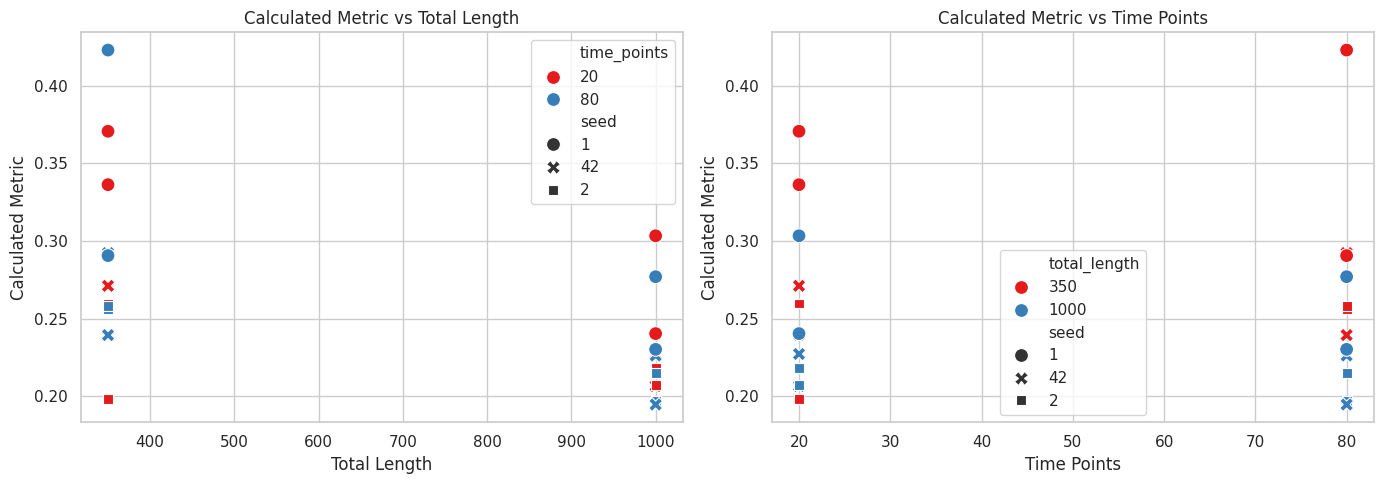

In [6]:

# List to hold the extracted data
results = []

# 2. Iterate through files, read them, and extract information
print("Scanning and processing files...")
for filepath in glob.glob(file_pattern):
    filename = os.path.basename(filepath)
    match = filename_regex.search(filename)
    
    if match:
        # Extract metadata from filename
        cells = int(match.group('cells'))
        genes = int(match.group('genes'))
        # Handle optional parameters (will be None if not in filename)
        total_len = int(match.group('total')) if match.group('total') else np.nan
        points = int(match.group('points')) if match.group('points') else np.nan
        seed = str(match.group('seed'))
        
        # Load the AnnData object
        try:
            adata = ad.read_h5ad(filepath)
            print(f"Successfully read {filename}")
            
            # --- REPLACE THIS WITH YOUR ACTUAL CALCULATION ---
            # Example calculation: Mean expression of all genes across all cells
            # Or extracting a specific metric from adata.uns or adata.obs
            if hasattr(adata.obsm['general_bound'], 'mean'):
                calc_metric = adata.obsm['general_bound'].mean()
            else:
                calc_metric = np.nan 
            # -------------------------------------------------
            
            # Store the results
            results.append({
                "filename": filename,
                "cells": cells,
                "genes": genes,
                "total_length": total_len,
                "time_points": points,
                "seed": seed,
                "general_bound": calc_metric # The data you want to plot
            })
            
        except Exception as e:
            print(f"Error reading {filename}: {e}")

# 3. Convert collected data to a DataFrame
df = pd.DataFrame(results)

# Drop rows that don't have 'total_length' or 'time_points'
plot_df = df.dropna(subset=['total_length', 'time_points']).copy()

# 4. Generate Scatter Plots
if not plot_df.empty:
    print("\nGenerating scatter plots...")
    sns.set_theme(style="whitegrid")
    
    # Create a figure with two subplots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Plot A: Metric vs Total Length (Dots only)
    # hue="seed" colors by seed, style="seed" gives each seed a different marker shape
    sns.scatterplot(
        data=plot_df, 
        x="total_length", 
        y="general_bound", 
        hue="time_points", 
        style="seed", 
        palette="Set1", # Use a discrete color palette
        s=100,          # Size of the dots
        ax=axes[0]
    )
    axes[0].set_title("Calculated Metric vs Total Length")
    axes[0].set_xlabel("Total Length")
    axes[0].set_ylabel("Calculated Metric")
    
    # Plot B: Metric vs Time Points (Dots only)
    sns.scatterplot(
        data=plot_df, 
        x="time_points", 
        y="general_bound", 
        hue="total_length", # Color by total_length for this plot
        style="seed",
        palette="Set1",
        s=100,
        ax=axes[1]
    )
    axes[1].set_title("Calculated Metric vs Time Points")
    axes[1].set_xlabel("Time Points")
    axes[1].set_ylabel("Calculated Metric")
    
    plt.tight_layout()
    plt.show()
    
else:
    print("\nNo files with 'total' and 'points' parameters were found for plotting.")

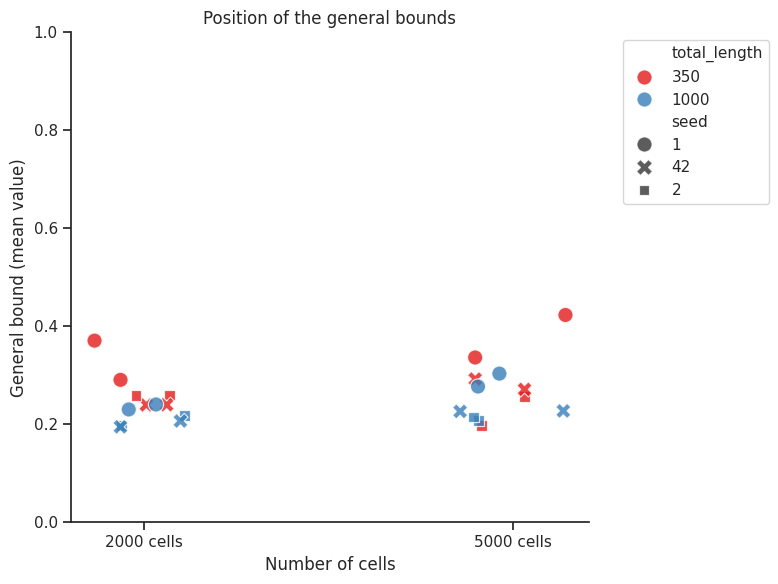

In [8]:
# 1. Change the theme to remove the background grid lines!
sns.set_theme(style="ticks") 

plt.figure(figsize=(8, 6))

# Map cell counts to base positions
unique_cells = sorted(plot_df['cells'].unique())
cell_to_x = {cells: i for i, cells in enumerate(unique_cells)}

# Add a simple random spread (jitter)
np.random.seed(42)
plot_df['x_jittered'] = plot_df['cells'].map(cell_to_x) + np.random.uniform(-0.15, 0.15, size=len(plot_df))

# Plot with scatterplot
sns.scatterplot(
    data=plot_df,
    x="x_jittered",
    y="general_bound",
    hue="total_length", 
    style="seed",       
    palette="Set1",
    s=120,              
    alpha=0.8
)

# Clean up axes
plt.xticks(ticks=range(len(unique_cells)), labels=[f"{c} cells" for c in unique_cells])
plt.ylim(0,1)
plt.title("Position of the general bounds")
plt.xlabel("Number of cells")
plt.ylabel("General bound (mean value)")

# 2. Optional but highly recommended: Remove the top and right border lines for a cleaner look
sns.despine()

# Move the legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Scanning and processing files...
Successfully read dynamical_trifurcating_5000_cells_500_genes_1000_total_20_points_seed_1.h5ad
Successfully read dynamical_trifurcating_5000_cells_2000_genes_100_total_3_points_seed_12.h5ad
Successfully read dynamical_trifurcating_5000_cells_500_genes_1000_total_20_points_seed_42.h5ad
Successfully read dynamical_trifurcating_10000_cells_2000_genes_100_total_80_points_seed_1.h5ad
Successfully read dynamical_trifurcating_2000_cells_500_genes_350_total_20_points_seed_2.h5ad
Successfully read dynamical_trifurcating_10000_cells_2000_genes_100_total_80_points_seed_42.h5ad
Successfully read dynamical_trifurcating_10000_cells_2000_genes_100_total_20_points_seed_1.h5ad
Successfully read dynamical_trifurcating_5000_cells_500_genes_350_total_80_points_seed_2.h5ad
Successfully read dynamical_trifurcating_5000_cells_2000_genes_100_total_3_points_seed_1.h5ad
Successfully read dynamical_trifurcating_5000_cells_500_genes_350_total_20_points_seed_1.h5ad
Successfully rea

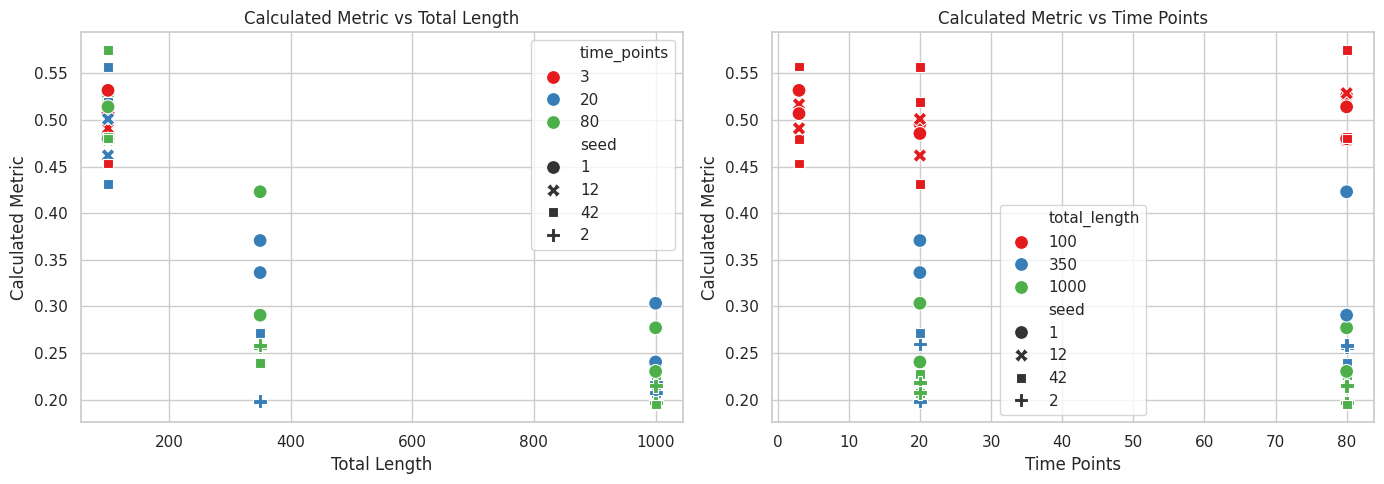

In [2]:
# 1. Define the directory containing your .h5ad files
# (Change this to your actual directory path, or use '.' for current directory)
data_dir = "/mnt/volume/Johanna_Velotest/sim_data" 
file_pattern = os.path.join(data_dir, "*.h5ad")

# Regex to extract parameters from the filename
# It makes 'total' and 'points' optional to handle both file types in your image
filename_regex = re.compile(
    r"dynamical_trifurcating_(?P<cells>\d+)_cells_(?P<genes>\d+)_genes"
    r"(?:_(?P<total>\d+)_total)?(?:_(?P<points>\d+)_points)?_seed_(?P<seed>\d+)\.h5ad"
)


# List to hold the extracted data
results = []

# 2. Iterate through files, read them, and extract information
print("Scanning and processing files...")
for filepath in glob.glob(file_pattern):
    filename = os.path.basename(filepath)
    match = filename_regex.search(filename)
    
    if match:
        # Extract metadata from filename
        cells = int(match.group('cells'))
        genes = int(match.group('genes'))
        # Handle optional parameters (will be None if not in filename)
        total_len = int(match.group('total')) if match.group('total') else np.nan
        points = int(match.group('points')) if match.group('points') else np.nan
        seed = str(match.group('seed'))
        
        # Load the AnnData object
        try:
            adata = ad.read_h5ad(filepath)
            print(f"Successfully read {filename}")
            
            # --- REPLACE THIS WITH YOUR ACTUAL CALCULATION ---
            # Example calculation: Mean expression of all genes across all cells
            # Or extracting a specific metric from adata.uns or adata.obs
            if hasattr(adata.obsm['general_bound'], 'mean'):
                calc_metric = adata.obsm['general_bound'].mean()
            else:
                calc_metric = np.nan 
            # -------------------------------------------------
            
            # Store the results
            results.append({
                "filename": filename,
                "cells": cells,
                "genes": genes,
                "total_length": total_len,
                "time_points": points,
                "seed": seed,
                "general_bound": calc_metric # The data you want to plot
            })
            
        except Exception as e:
            print(f"Error reading {filename}: {e}")

# 3. Convert collected data to a DataFrame
df = pd.DataFrame(results)

# Drop rows that don't have 'total_length' or 'time_points'
plot_df = df.dropna(subset=['total_length', 'time_points']).copy()

# 4. Generate Scatter Plots
if not plot_df.empty:
    print("\nGenerating scatter plots...")
    sns.set_theme(style="whitegrid")
    
    # Create a figure with two subplots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Plot A: Metric vs Total Length (Dots only)
    # hue="seed" colors by seed, style="seed" gives each seed a different marker shape
    sns.scatterplot(
        data=plot_df, 
        x="total_length", 
        y="general_bound", 
        hue="time_points", 
        style="seed", 
        palette="Set1", # Use a discrete color palette
        s=100,          # Size of the dots
        ax=axes[0]
    )
    axes[0].set_title("Calculated Metric vs Total Length")
    axes[0].set_xlabel("Total Length")
    axes[0].set_ylabel("Calculated Metric")
    
    # Plot B: Metric vs Time Points (Dots only)
    sns.scatterplot(
        data=plot_df, 
        x="time_points", 
        y="general_bound", 
        hue="total_length", # Color by total_length for this plot
        style="seed",
        palette="Set1",
        s=100,
        ax=axes[1]
    )
    axes[1].set_title("Calculated Metric vs Time Points")
    axes[1].set_xlabel("Time Points")
    axes[1].set_ylabel("Calculated Metric")
    
    plt.tight_layout()
    plt.show()
    
else:
    print("\nNo files with 'total' and 'points' parameters were found for plotting.")

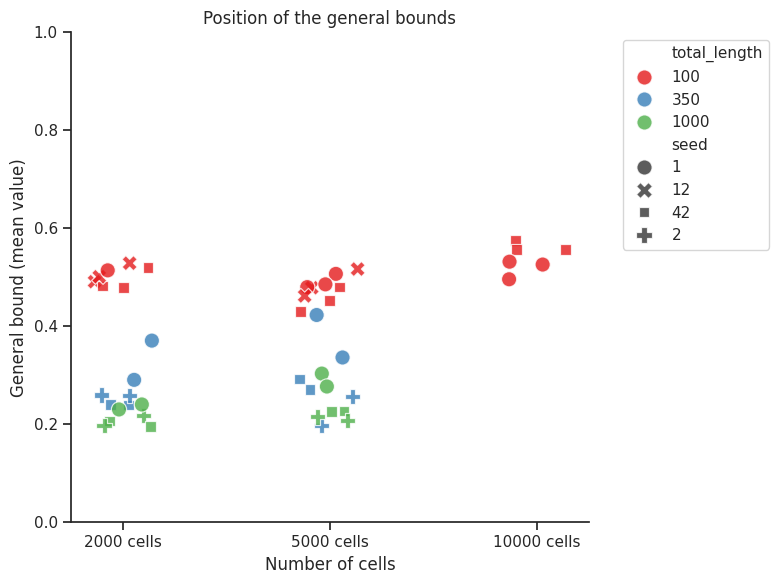

In [5]:
# 1. Change the theme to remove the background grid lines!
sns.set_theme(style="ticks") 

plt.figure(figsize=(8, 6))

# Map cell counts to base positions
unique_cells = sorted(plot_df['cells'].unique())
cell_to_x = {cells: i for i, cells in enumerate(unique_cells)}

# Add a simple random spread (jitter)
np.random.seed(42)
plot_df['x_jittered'] = plot_df['cells'].map(cell_to_x) + np.random.uniform(-0.15, 0.15, size=len(plot_df))

# Plot with scatterplot
sns.scatterplot(
    data=plot_df,
    x="x_jittered",
    y="general_bound",
    hue="total_length", 
    style="seed",       
    palette="Set1",
    s=120,              
    alpha=0.8
)

# Clean up axes
plt.xticks(ticks=range(len(unique_cells)), labels=[f"{c} cells" for c in unique_cells])
plt.ylim(0,1)
plt.title("Position of the general bounds")
plt.xlabel("Number of cells")
plt.ylabel("General bound (mean value)")

# 2. Optional but highly recommended: Remove the top and right border lines for a cleaner look
sns.despine()

# Move the legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()